# S&P 500 週足 メディアン統計とモメンタム

In [1]:
import sys

path_up = ".."
if not path_up in sys.path:
    sys.path.append(path_up)

In [2]:
import datetime
import os

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import mplfinance as mpf
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
import yfinance as yf
from scipy import stats

from funcs.technical import calc_robust_bollinger

In [3]:
code = "GSPC"
symbol = "^%s" % code
yticker = yf.Ticker(symbol)

In [4]:
### 最新のデータが取得されていることを確認 ###
yticker.history(period="7d", interval="1d")

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-06 00:00:00-05:00,7377.649902,7444.200195,7369.549805,7376.859863,5701900000,0.0,0.0
2026-11-09 00:00:00-05:00,7422.240234,7577.390137,7422.240234,7549.939941,5819360000,0.0,0.0
2026-11-10 00:00:00-05:00,7513.089844,7543.919922,7470.430176,7520.930176,5056350000,0.0,0.0
2026-11-11 00:00:00-05:00,7586.649902,7647.200195,7571.879883,7619.379883,4493200000,0.0,0.0
2026-11-12 00:00:00-05:00,7550.839844,7652.759766,7550.839844,7592.399902,4693040000,0.0,0.0
2026-11-13 00:00:00-05:00,7616.850098,7621.779785,7499.399902,7561.669922,4372990000,0.0,0.0
2026-11-16 00:00:00-05:00,7513.979980,7515.600098,7400.149902,7416.589844,3040201000,0.0,0.0


In [5]:
# 週足で過去 5 年分のデータを取得
df0 = yticker.history(period="10y", interval="1wk")

# ローソク足のチャートには、そのうち過去 3 年分のみ使用する
dt_last = df0.index[len(df0) - 1]
tdelta_2y = datetime.timedelta(days=365 * 2)
df = df0[df0.index >= dt_last - tdelta_2y]

In [6]:
dt = df.tail(1).index[0]
year_str = f"{dt.year:04d}"
date_str = f"{dt.month:02d}{dt.day:02d}"
date_str

'1116'

## Moving Median

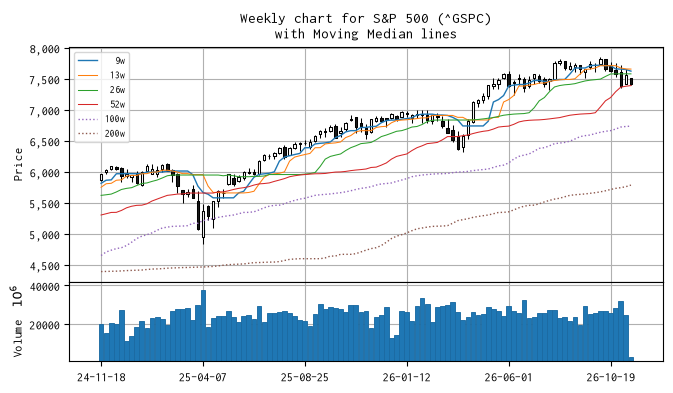

In [7]:
FONT_PATH = "../fonts/RictyDiminished-Regular.ttf"
fm.fontManager.addfont(FONT_PATH)

# FontPropertiesオブジェクト生成（名前の取得のため）
font_prop = fm.FontProperties(fname=FONT_PATH)
font_prop.get_name()

plt.rcParams["font.family"] = font_prop.get_name()
plt.rcParams["font.size"] = 9

fig = plt.figure(figsize=(6.8, 4))
ax = dict()
n = 2
gs = fig.add_gridspec(
    n, 1, wspace=0.0, hspace=0.0, height_ratios=[3 if i == 0 else 1 for i in range(n)]
)
for i, axis in enumerate(gs.subplots(sharex="col")):
    ax[i] = axis
    ax[i].grid()

mm09 = df0["Close"].rolling(9).median()
mm13 = df0["Close"].rolling(13).median()
mm26 = df0["Close"].rolling(26).median()
mm52 = df0["Close"].rolling(52).median()
mm100 = df0["Close"].rolling(100).median()
mm200 = df0["Close"].rolling(200).median()

apds = [
    mpf.make_addplot(mm09[df.index], width=1, label="  9w", ax=ax[0]),
    mpf.make_addplot(mm13[df.index], width=0.75, label=" 13w", ax=ax[0]),
    mpf.make_addplot(mm26[df.index], width=0.75, label=" 26w", ax=ax[0]),
    mpf.make_addplot(mm52[df.index], width=0.75, label=" 52w", ax=ax[0]),
    mpf.make_addplot(
        mm100[df.index],
        width=1,
        linestyle="dotted",
        label="100w",
        ax=ax[0],
    ),
    mpf.make_addplot(
        mm200[df.index],
        width=1,
        linestyle="dotted",
        label="200w",
        ax=ax[0],
    ),
]

mpf.plot(
    df,
    type="candle",
    style="default",
    volume=ax[1],
    datetime_format="%y-%m-%d",
    addplot=apds,
    xrotation=0,
    update_width_config=dict(candle_linewidth=0.75),
    ax=ax[0],
)

ax[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax[0].set_title(
    f"Weekly chart for {yticker.info["longName"]} ({symbol})\nwith Moving Median lines"
)
ax[0].legend(loc="upper left", fontsize=7)

plt.tight_layout()
os.makedirs(year_str, exist_ok=True)
plt.savefig(os.path.join(year_str, f"{date_str}_report_weekly_chart_median_{code}.png"))
plt.show()

In [8]:
df.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-09 00:00:00-05:00,7422.240234,7652.759766,7422.240234,7561.669922,24434940000,0.0,0.0
2026-11-16 00:00:00-05:00,7513.979980,7515.600098,7400.149902,7416.589844,3040205000,0.0,0.0


In [9]:
df.tail(2)["Close"]

Date
2026-11-09 00:00:00-05:00    7561.669922
2026-11-16 00:00:00-05:00    7416.589844
Freq: W-MON, Name: Close, dtype: float64

In [10]:
df.tail(2)["Close"].diff()

Date
2026-11-09 00:00:00-05:00           NaN
2026-11-16 00:00:00-05:00   -145.080078
Freq: W-MON, Name: Close, dtype: float64

In [11]:
df["Close"].rolling(9).median().tail(10)

Date
2026-09-14 00:00:00-04:00    7674.370117
2026-09-21 00:00:00-04:00    7711.759766
2026-09-28 00:00:00-04:00    7718.600098
2026-10-05 00:00:00-04:00    7718.600098
2026-10-12 00:00:00-04:00    7711.759766
2026-10-19 00:00:00-04:00    7711.759766
2026-10-26 00:00:00-04:00    7659.439941
2026-11-02 00:00:00-05:00    7656.979980
2026-11-09 00:00:00-05:00    7650.500000
2026-11-16 00:00:00-05:00    7623.680176
Freq: W-MON, Name: Close, dtype: float64

In [12]:
df["Close"].rolling(13).median().tail(10)

Date
2026-09-14 00:00:00-04:00    7650.500000
2026-09-21 00:00:00-04:00    7656.979980
2026-09-28 00:00:00-04:00    7674.370117
2026-10-05 00:00:00-04:00    7711.759766
2026-10-12 00:00:00-04:00    7711.759766
2026-10-19 00:00:00-04:00    7711.759766
2026-10-26 00:00:00-04:00    7711.759766
2026-11-02 00:00:00-05:00    7674.370117
2026-11-09 00:00:00-05:00    7659.439941
2026-11-16 00:00:00-05:00    7656.979980
Freq: W-MON, Name: Close, dtype: float64

In [13]:
df["Close"].rolling(26).median().tail(5)

Date
2026-10-19 00:00:00-04:00    7577.725098
2026-10-26 00:00:00-04:00    7580.064941
2026-11-02 00:00:00-05:00    7580.064941
2026-11-09 00:00:00-05:00    7580.064941
2026-11-16 00:00:00-05:00    7580.064941
Freq: W-MON, Name: Close, dtype: float64

In [14]:
df["Close"].rolling(52).median().tail(5)

Date
2026-10-19 00:00:00-04:00    7197.600098
2026-10-26 00:00:00-04:00    7292.070068
2026-11-02 00:00:00-05:00    7365.439941
2026-11-09 00:00:00-05:00    7380.300049
2026-11-16 00:00:00-05:00    7391.335205
Freq: W-MON, Name: Close, dtype: float64

In [15]:
df0["Close"].rolling(100).median().tail(5)

Date
2026-10-19 00:00:00-04:00    6664.184814
2026-10-26 00:00:00-04:00    6690.074951
2026-11-02 00:00:00-05:00    6722.294922
2026-11-09 00:00:00-05:00    6731.454834
2026-11-16 00:00:00-05:00    6737.064941
Freq: W-MON, Name: Close, dtype: float64

In [16]:
df0["Close"].rolling(200).median().tail(5)

Date
2026-10-19 00:00:00-04:00    5715.674805
2026-10-26 00:00:00-04:00    5733.484863
2026-11-02 00:00:00-05:00    5744.619873
2026-11-09 00:00:00-05:00    5760.635010
2026-11-16 00:00:00-05:00    5786.510010
Freq: W-MON, Name: Close, dtype: float64

## Robust Bollinger bands

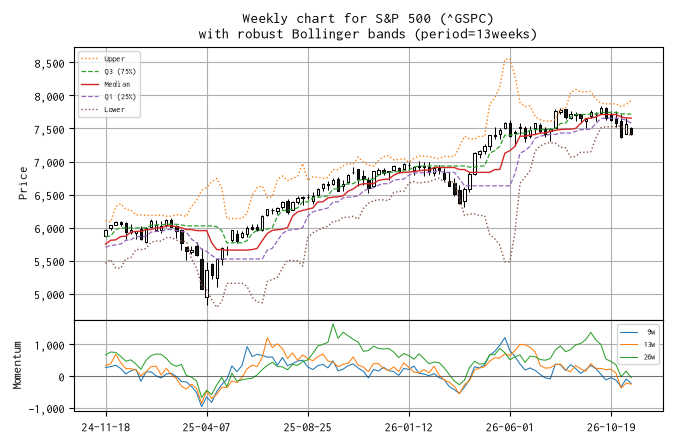

In [17]:
FONT_PATH = "../fonts/RictyDiminished-Regular.ttf"
fm.fontManager.addfont(FONT_PATH)

# FontPropertiesオブジェクト生成（名前の取得のため）
font_prop = fm.FontProperties(fname=FONT_PATH)
font_prop.get_name()

plt.rcParams["font.family"] = font_prop.get_name()
plt.rcParams["font.size"] = 9

# fig, ax = plt.subplots(figsize=(6, 3.5))
fig = plt.figure(figsize=(6.8, 4.5))
ax = dict()
n = 2
gs = fig.add_gridspec(
    n, 1, wspace=0.0, hspace=0.0, height_ratios=[3 if i == 0 else 1 for i in range(n)]
)
for i, axis in enumerate(gs.subplots(sharex="col")):
    ax[i] = axis
    ax[i].grid()

# Bollinger bands
period = 13
mv_median = df0["Close"].rolling(period).median()
mv_q1 = df0["Close"].rolling(period).quantile(0.25)
mv_q3 = df0["Close"].rolling(period).quantile(0.75)
mv_iqr = mv_q3 - mv_q1
mv_lower = mv_q1 - mv_iqr * 1.5
mv_upper = mv_q3 + mv_iqr * 1.5

mom09 = df0["Close"] - df0["Close"].shift(9, axis=0)
mom13 = df0["Close"] - df0["Close"].shift(13, axis=0)
mom26 = df0["Close"] - df0["Close"].shift(26, axis=0)

apds = [
    mpf.make_addplot(
        mv_upper[df.index],
        width=1,
        color="C1",
        linestyle="dotted",
        label="Upper",
        ax=ax[0],
    ),
    mpf.make_addplot(
        mv_q3[df.index],
        width=0.9,
        color="C2",
        linestyle="dashed",
        label="Q3 (75%)",
        ax=ax[0],
    ),
    mpf.make_addplot(
        mv_median[df.index],
        width=1,
        color="C3",
        linestyle="solid",
        label="Median",
        ax=ax[0],
    ),
    mpf.make_addplot(
        mv_q1[df.index],
        width=0.9,
        color="C4",
        linestyle="dashed",
        label="Q1 (25%)",
        ax=ax[0],
    ),
    mpf.make_addplot(
        mv_lower[df.index],
        width=1,
        color="C5",
        linestyle="dotted",
        label="Lower",
        ax=ax[0],
    ),
    mpf.make_addplot(
        mom09[df.index],
        width=0.75,
        linestyle="solid",
        label=" 9w",
        ax=ax[1],
    ),
    mpf.make_addplot(
        mom13[df.index],
        width=0.75,
        linestyle="solid",
        label="13w",
        ax=ax[1],
    ),
    mpf.make_addplot(
        mom26[df.index],
        width=0.75,
        linestyle="solid",
        label="26w",
        ax=ax[1],
    ),
]

mpf.plot(
    df,
    type="candle",
    style="default",
    addplot=apds,
    datetime_format="%y-%m-%d",
    xrotation=0,
    update_width_config=dict(candle_linewidth=0.75),
    ax=ax[0],
)

# ax.grid()
ax[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax[0].legend(loc="best", fontsize=6)

ax[1].axhline(y=0, color="black", alpha=0.5, linewidth=0.5)
ax[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax[1].set_ylabel("Momentum")
ax[1].legend(loc="best", fontsize=6)

try:
    ax[0].set_title(
        f"Weekly chart for {yticker.info['longName']} ({symbol})\nwith robust Bollinger bands (period={period}weeks)"
    )
except KeyError:
    ax[0].set_title(
        f"Weekly chart for {symbol}\nwith robust Bollinger bands (period={period}weeks)"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(
        year_str, f"{date_str}_report_weekly_chart_bollinger_robust_{code}.png"
    )
)
plt.show()

## ヒストグラムと Q-Q プロット

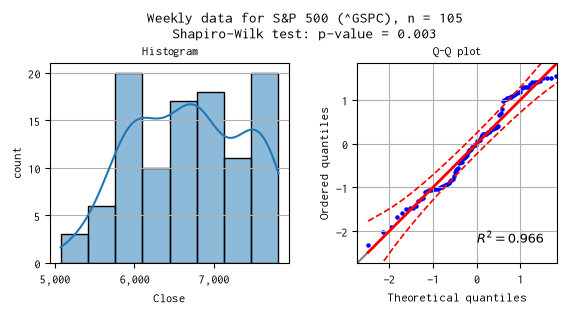

In [18]:
plt.rcParams["font.size"] = 9
fig, axes = plt.subplots(1, 2, figsize=(6.8, 3))

sns.histplot(df["Close"], kde=True, ax=axes[0])

# ヒストグラム
axes[0].set_xlabel("Close")
axes[0].set_ylabel("count")
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
axes[0].grid(axis="y")
axes[0].set_title("Histogram", fontsize=9)

# Q-Q プロット
pg.qqplot(df["Close"], s=5, ax=axes[1])
axes[1].set_title("Q-Q plot", fontsize=9)
axes[1].grid()

shapiro_test = stats.shapiro(df["Close"])
title_str = (
    f"Weekly data for {yticker.info["longName"]} ({symbol}), n = {len(df)}\n"
    f"Shapiro-Wilk test: p-value = {shapiro_test.pvalue:.3f}"
)
plt.suptitle(
    title_str,
    fontsize=11,
)
plt.subplots_adjust(top=0.80, bottom=0.135, wspace=0.2)
plt.savefig(
    os.path.join(year_str, f"{date_str}_report_weekly_histogram_qqplot_{code}.png")
)
plt.show()